# Russian silver quality audit: gen4k vs gen8k

Reproducible low-cost audit of schema validity, span fidelity, distribution drift, lexical diversity, and the already-completed paired-seed decision gate. Automated proxies do **not** establish semantic label correctness; a deterministic 100-row sample is exported separately for human adjudication.

In [1]:
from pathlib import Path
import importlib.util, json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'scripts/analyze_rus_silver_quality.py').exists():
    ROOT = ROOT.parent
spec = importlib.util.spec_from_file_location('silver_audit', ROOT / 'scripts/analyze_rus_silver_quality.py')
silver_audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(silver_audit)
metrics = silver_audit.run_analysis(sample_size=3000)
print('Inputs:', metrics['source_files'])

Inputs: {'gen4k': 'data/subtask_3/rus/rus_restaurant_silver_v23_deepseek_gen4k.jsonl', 'gen8k': 'data/subtask_3/rus/rus_restaurant_silver_v23_deepseek_gen.jsonl', 'gold': 'data/subtask_3/rus/rus_restaurant_train_alltasks.jsonl', 'test': 'data/subtask_3/rus/rus_restaurant_test_task3.jsonl'}


## Core data-quality indicators

In [2]:
rows = []
for batch in ('gen4k', 'gen8k'):
    x = metrics['batches'][batch]
    rows.append({
        'batch': batch, 'rows': x['rows'], 'invalid_rows': x['invalid_rows'],
        'duplicate_rows': x['normalized_duplicate_rows'],
        'quads_per_row': x['quadruplets_per_row']['mean'],
        'category_JSD_vs_gold': x['category_jsd_vs_gold'],
        'category_top_share': x['category_top_share'],
        'MSTTR_100_equal_n': x['equal_size_lexical_sample']['msttr_100'],
        'unigram_novelty_equal_n': x['equal_size_lexical_sample']['unigram_novelty_vs_reference'],
    })
quality = pd.DataFrame(rows).set_index('batch')
quality.round(4)

,rows,invalid_rows,duplicate_rows,quads_per_row,category_JSD_vs_gold,category_top_share,MSTTR_100_equal_n,unigram_novelty_equal_n
batch,,,,,,,,
gen4k,4000,10,0,2.4812,0.0651,0.262,0.8843,0.6505
gen8k,8000,31,0,2.4346,0.0719,0.292,0.8833,0.6388


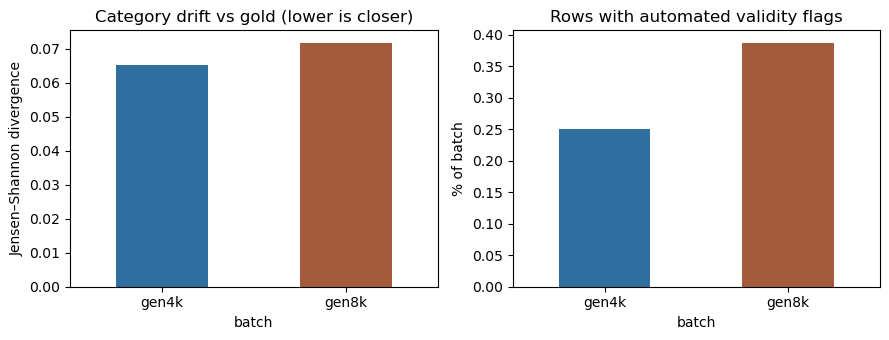

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
quality['category_JSD_vs_gold'].plot.bar(ax=axes[0], color=['#2f6f9f', '#a55b3b'], rot=0)
axes[0].set_title('Category drift vs gold (lower is closer)')
axes[0].set_ylabel('Jensen–Shannon divergence')
quality['invalid_rows'].div(quality['rows']).mul(100).plot.bar(ax=axes[1], color=['#2f6f9f', '#a55b3b'], rot=0)
axes[1].set_title('Rows with automated validity flags')
axes[1].set_ylabel('% of batch')
plt.tight_layout(); plt.show()

## Decision evidence

In [4]:
paired = metrics['comparisons']['paired_seed_dev_cf1']
performance = pd.DataFrame({
    'gen8k full': [paired['gen8k_full']['seed42'], paired['gen8k_full']['seed123']],
    'same-pool cap3000': [paired['gen8k_cap3000']['seed42'], paired['gen8k_cap3000']['seed123']],
}, index=['seed42', 'seed123'])
performance.loc['mean'] = performance.mean()
performance.round(4)

,gen8k full,same-pool cap3000
seed42,0.5286,0.5123
seed123,0.5648,0.5584
mean,0.5467,0.5354


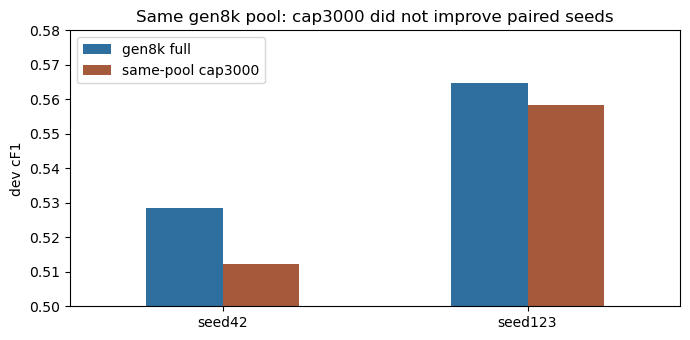

In [5]:
ax = performance.loc[['seed42', 'seed123']].plot.bar(figsize=(7, 3.5), rot=0, color=['#2f6f9f', '#a55b3b'])
ax.set_ylabel('dev cF1'); ax.set_ylim(0.50, 0.58)
ax.set_title('Same gen8k pool: cap3000 did not improve paired seeds')
plt.tight_layout(); plt.show()

## Interpretation

- The same-pool cap3000 mean is 1.14pp below the full-gen8k paired mean, so the pre-registered +1.5pp continuation gate failed. No remaining seeds or cap5000 curve are warranted.
- gen4k is slightly closer to gold in category distribution and has fewer flagged rows proportionally, but the proxy differences are small. The strong performance gap is therefore consistent with — but does not independently prove — higher semantic quality in the gen4k generation batch.
- The defensible conclusion is batch-quality sensitivity, not a universal 3k optimum.

## Limitations and manual-review handoff

The 100-row file at `docs/audits/rus_silver_manual_sample_100.jsonl` contains 50 deterministic examples per batch with empty `manual_label_correct` and `manual_notes` fields. Until a Russian-speaking reviewer fills those fields, no human-adjudicated precision claim should be reported.